# 02. Pemodelan K-Modes Clustering Berbasis Pemisahan Wilayah (Region-Partitioning)
---

### **Tujuan Notebook:**
1. Memuat dataset kategorikal bersih (`01_umkm_clean.csv`, periode 2024, ~266.678 baris).
2. Mempartisi data ke dalam 6 wilayah administrasi DKI Jakarta.
3. Menjalankan algoritma *K-Modes Clustering* dengan fungsi *matching dissimilarity* dan inisialisasi `Cao` pada **2 atribut kategorikal**: `sektor_makro` dan `kelompok_tahun_berdiri`.
4. Menghitung kurva *Elbow* (`cost_` vs $k=2..6$) per wilayah sebagai dasar pemilihan jumlah klaster final, dikombinasikan dengan pertimbangan kepraktisan interpretasi -- tanpa metrik kedua yang dihitung bersamaan.
5. Menyematkan label klaster final pada masing-masing wilayah dan mengekstrak profil dominan tiap klaster.
6. Menyimpan dataset terklasterisasi ke `data/processed/02_umkm_kmodes_clustered.csv` dan ringkasan biaya Elbow ke `data/processed/02b_elbow_costs.csv`.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from kmodes.kmodes import KModes

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

print("Pustaka K-Modes berhasil dimuat.")

Pustaka K-Modes berhasil dimuat.


## 1. Memuat Dataset Hasil Rekayasa Fitur
Memuat dataset `01_umkm_clean.csv` (periode 2024, ~266.678 baris bersih) beserta 2 fitur kategorikal siap olah: `sektor_makro`, `kelompok_tahun_berdiri`.

In [2]:
data_path = os.path.join('..', 'data', 'processed', '01_umkm_clean.csv')
if not os.path.exists(data_path):
    data_path = '01_umkm_clean.csv'

df = pd.read_csv(data_path)
FEATURES = ['sektor_makro', 'kelompok_tahun_berdiri']

print(f"Dataset berhasil dimuat: {len(df):,} baris.")
df[['wilayah'] + FEATURES].head(5)

Dataset berhasil dimuat: 266,678 baris.


,wilayah,sektor_makro,kelompok_tahun_berdiri
0,KOTA ADM. JAKARTA PUSAT,Kriya & Industri Kreatif,Usaha Lama (2020-2021)
1,KOTA ADM. JAKARTA SELATAN,Kuliner & Pangan Olahan,Usaha Lama (2020-2021)
2,KAB. ADM. KEP. SERIBU,"Jasa, Teknologi & Otomotif",Usaha Lama (2020-2021)
3,KOTA ADM. JAKARTA PUSAT,Kuliner & Pangan Olahan,Usaha Lama (2020-2021)
4,KOTA ADM. JAKARTA TIMUR,Kuliner & Pangan Olahan,Usaha Berkembang (2022-2023)


## 2. Fungsi Pemodelan K-Modes per Partisi Wilayah
Algoritma *K-Modes* mengelompokkan data berdasarkan ketidaksamaan pencocokan sederhana (*simple matching dissimilarity*) pada 2 atribut kategorikal (`FEATURES`).

In [3]:
def train_kmodes_region(df_subset, features, n_clusters=3, n_init=5, random_state=42):
    """
    Melatih model K-Modes untuk satu wilayah administrasi pada 2 fitur kategorikal.
    """
    df_reg = df_subset.copy()

    # Matriks fitur kategorikal (2 atribut)
    feature_matrix = df_reg[features].values

    # Inisialisasi K-Modes dengan metode Cao
    km = KModes(
        n_clusters=n_clusters,
        init='Cao',
        n_init=n_init,
        verbose=0,
        random_state=random_state,
        n_jobs=1
    )

    t_start = time.time()
    clusters = km.fit_predict(feature_matrix)
    t_elapsed = time.time() - t_start

    df_reg['cluster'] = clusters

    print(f"Fitting K-Modes selesai ({t_elapsed:.2f} dtk) | k={n_clusters} | Nilai Cost: {km.cost_:,}")
    return df_reg, km

## 3. Kurva Elbow (Cost vs $k$) per Wilayah
Menjalankan K-Modes untuk $k = 2$ hingga $k = 6$ pada **2 fitur** (`sektor_makro`, `kelompok_tahun_berdiri`) di setiap wilayah administrasi, guna mengamati laju penurunan `cost_` (total *matching dissimilarity*) seiring bertambahnya jumlah klaster. Kurva ini jadi dasar tunggal pemilihan $k$ final di Bagian 4 -- tidak ada metrik kedua yang dihitung bersamaan.

=== MENGHITUNG KURVA ELBOW (k=2..6) PER WILAYAH ===

--- Wilayah: KAB. ADM. KEP. SERIBU ---
  k=2 -> Cost: 2,381.0
  k=3 -> Cost: 1,535.0
  k=4 -> Cost: 1,084.0
  k=5 -> Cost: 840.0
  k=6 -> Cost: 693.0

--- Wilayah: KOTA ADM. JAKARTA BARAT ---
  k=2 -> Cost: 19,486.0
  k=3 -> Cost: 15,056.0
  k=4 -> Cost: 11,929.0
  k=5 -> Cost: 9,362.0
  k=6 -> Cost: 7,090.0

--- Wilayah: KOTA ADM. JAKARTA PUSAT ---
  k=2 -> Cost: 15,423.0
  k=3 -> Cost: 10,234.0
  k=4 -> Cost: 8,787.0
  k=5 -> Cost: 7,156.0
  k=6 -> Cost: 5,597.0

--- Wilayah: KOTA ADM. JAKARTA SELATAN ---
  k=2 -> Cost: 31,636.0
  k=3 -> Cost: 20,163.0
  k=4 -> Cost: 16,900.0
  k=5 -> Cost: 12,987.0
  k=6 -> Cost: 9,966.0

--- Wilayah: KOTA ADM. JAKARTA TIMUR ---
  k=2 -> Cost: 24,808.0
  k=3 -> Cost: 18,387.0
  k=4 -> Cost: 15,430.0
  k=5 -> Cost: 11,562.0
  k=6 -> Cost: 9,802.0

--- Wilayah: KOTA ADM. JAKARTA UTARA ---
  k=2 -> Cost: 18,695.0
  k=3 -> Cost: 14,075.0
  k=4 -> Cost: 10,851.0
  k=5 -> Cost: 7,844.0
  k=6 -> Cost: 6,

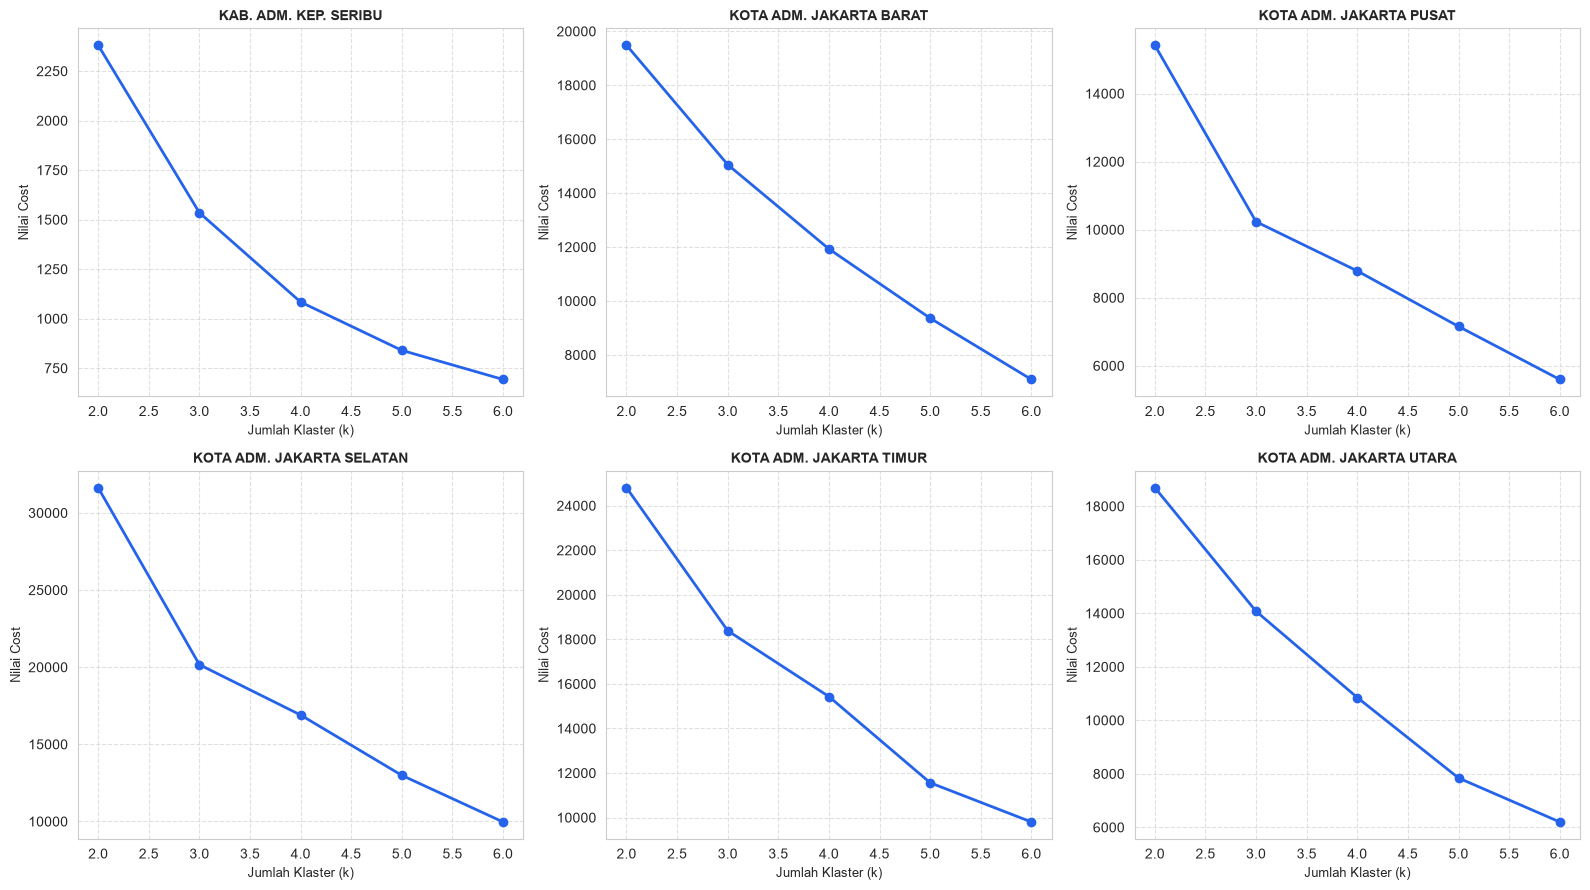


=== KURVA ELBOW SELESAI DIHITUNG UNTUK SELURUH WILAYAH ===


In [4]:
daftar_wilayah = sorted(df['wilayah'].unique().tolist())

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

elbow_records = []

print("=== MENGHITUNG KURVA ELBOW (k=2..6) PER WILAYAH ===")
for idx, wil in enumerate(daftar_wilayah):
    print(f"\n--- Wilayah: {wil} ---")
    df_wil = df[df['wilayah'] == wil]
    X_wil = df_wil[FEATURES].values

    k_vals, costs = [], []
    for k in range(2, 7):
        km = KModes(n_clusters=k, init='Cao', n_init=5, verbose=0, random_state=42, n_jobs=1)
        km.fit(X_wil)
        k_vals.append(k)
        costs.append(km.cost_)
        elbow_records.append({'wilayah': wil, 'k': k, 'cost': km.cost_})
        print(f"  k={k} -> Cost: {km.cost_:,}")

    axes[idx].plot(k_vals, costs, marker='o', color='#2563EB', linewidth=2, markersize=6)
    axes[idx].set_title(f"{wil}", fontsize=10, fontweight='bold')
    axes[idx].set_xlabel("Jumlah Klaster (k)", fontsize=9)
    axes[idx].set_ylabel("Nilai Cost", fontsize=9)
    axes[idx].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

df_elbow = pd.DataFrame(elbow_records)
print("\n=== KURVA ELBOW SELESAI DIHITUNG UNTUK SELURUH WILAYAH ===")

## 4. Pemilihan $k$ Final & Model Produksi

**Prosedur:**
1. Model dijalankan untuk $k=2..6$ tiap wilayah pada 2 fitur (Bagian 3 di atas).
2. Dicari kandidat $k$ di mana penurunan `cost_` mulai melandai (elbow) -- murni dari kurva biaya, tanpa metrik kedua yang dihitung bersamaan.
3. Kepraktisan interpretasi (jumlah klaster tidak berlebihan untuk ditampilkan sebagai kartu profil segmen) jadi pertimbangan akhir kalau kurva Elbow tidak konklusif sendirian di sebagian wilayah.

Bukti kuantitatif untuk prosedur ini dihitung langsung dari `df_elbow` di atas pada cell berikut (bukan angka manual):

In [5]:
print("=== RINGKASAN COST PER k, PER WILAYAH ===")
ringkasan_k = df_elbow.pivot(index='k', columns='wilayah', values='cost')
print(ringkasan_k.round(2))

print("\n=== PENURUNAN COST MARGINAL (%) PER TRANSISI k, PER WILAYAH ===")
cost_pct_turun = (-ringkasan_k.pct_change() * 100).dropna()
print(cost_pct_turun.round(1))

print("\n=== WILAYAH DENGAN PENURUNAN COST TERBESAR DI TIAP TRANSISI k ===")
for k_to in cost_pct_turun.index:
    terbesar = cost_pct_turun.loc[k_to].idxmax()
    print(f"  k={k_to - 1}->{k_to}: penurunan terbesar di {terbesar} ({cost_pct_turun.loc[k_to, terbesar]:.1f}%)")

n_wilayah_knee_di_3 = int((cost_pct_turun.loc[3] == cost_pct_turun.max()).sum())
print(f"\nJumlah wilayah dengan penurunan cost TERBESAR tepat di k=2->3: {n_wilayah_knee_di_3} dari {cost_pct_turun.shape[1]}")

=== RINGKASAN COST PER k, PER WILAYAH ===
wilayah  KAB. ADM. KEP. SERIBU  KOTA ADM. JAKARTA BARAT  \
k                                                         
2                       2381.0                  19486.0   
3                       1535.0                  15056.0   
4                       1084.0                  11929.0   
5                        840.0                   9362.0   
6                        693.0                   7090.0   

wilayah  KOTA ADM. JAKARTA PUSAT  KOTA ADM. JAKARTA SELATAN  \
k                                                             
2                        15423.0                    31636.0   
3                        10234.0                    20163.0   
4                         8787.0                    16900.0   
5                         7156.0                    12987.0   
6                         5597.0                     9966.0   

wilayah  KOTA ADM. JAKARTA TIMUR  KOTA ADM. JAKARTA UTARA  
k                                         

**Keputusan -- $k$ final = 3, untuk seluruh wilayah:**

Berdasarkan output di atas: mayoritas wilayah menunjukkan penurunan `cost_` terbesar tepat di transisi $k=2 \to 3$ (lihat "Jumlah wilayah dengan penurunan cost terbesar tepat di k=2->3"), lalu penurunan melandai relatif tidak setajam itu lagi untuk $k=4,5,6$ pada sebagian besar wilayah. Kepraktisan interpretasi turut mendukung: $k=3$ tetap ringkas untuk kartu profil segmen dan heatmap sektor × usia usaha di `03_interpretasi_dan_klasifikasi_ocean.ipynb`, dibanding $k$ yang lebih besar yang menambah kompleksitas tanpa siku elbow yang jelas.

Model final di bawah ini dilatih ulang per wilayah pada $k=3$ dengan `n_init=5` agar hasil pelabelan klaster stabil, lalu disimpan sebagai dataset produksi (dipakai oleh `03_interpretasi_dan_klasifikasi_ocean.ipynb` dan `app.py`).

In [6]:
K_FINAL = 3
clustered_list = []
model_dict = {}

print(f"=== MELATIH MODEL PRODUKSI K-MODES (k={K_FINAL}) PER WILAYAH ===")
for wil in daftar_wilayah:
    print(f"\n--- Wilayah: {wil} ---")
    df_wil = df[df['wilayah'] == wil].copy()

    df_clustered_wil, model_wil = train_kmodes_region(df_wil, FEATURES, n_clusters=K_FINAL, n_init=5, random_state=42)

    clustered_list.append(df_clustered_wil)
    model_dict[wil] = model_wil

# Menggabungkan seluruh data yang telah terklasterisasi
df_final = pd.concat(clustered_list, ignore_index=True)
print("\n=== CLUSTERING K-MODES SELURUH WILAYAH SELESAI ===")
print(f"Total baris data terklasterisasi: {len(df_final):,} baris")

=== MELATIH MODEL PRODUKSI K-MODES (k=3) PER WILAYAH ===

--- Wilayah: KAB. ADM. KEP. SERIBU ---
Fitting K-Modes selesai (0.12 dtk) | k=3 | Nilai Cost: 1,535.0

--- Wilayah: KOTA ADM. JAKARTA BARAT ---
Fitting K-Modes selesai (1.34 dtk) | k=3 | Nilai Cost: 15,056.0

--- Wilayah: KOTA ADM. JAKARTA PUSAT ---
Fitting K-Modes selesai (0.94 dtk) | k=3 | Nilai Cost: 10,234.0

--- Wilayah: KOTA ADM. JAKARTA SELATAN ---
Fitting K-Modes selesai (1.80 dtk) | k=3 | Nilai Cost: 20,163.0

--- Wilayah: KOTA ADM. JAKARTA TIMUR ---
Fitting K-Modes selesai (1.49 dtk) | k=3 | Nilai Cost: 18,387.0

--- Wilayah: KOTA ADM. JAKARTA UTARA ---
Fitting K-Modes selesai (1.22 dtk) | k=3 | Nilai Cost: 14,075.0

=== CLUSTERING K-MODES SELURUH WILAYAH SELESAI ===
Total baris data terklasterisasi: 266,678 baris


## 5. Ekstraksi Modus Pusat Klaster (*Cluster Modes*)
Melihat nilai modus representatif (kombinasi `sektor_makro`, `kelompok_tahun_berdiri`) yang menjadi pusat setiap klaster.

In [7]:
for wil in daftar_wilayah:
    km_model = model_dict[wil]
    print(f"\n==================================================")
    print(f"PUSAT MODUS: {wil}")
    print(f"==================================================")
    for c_id, mode_val in enumerate(km_model.cluster_centroids_):
        print(f"  Klaster {c_id} -> Sektor: '{mode_val[0]}' | Usia Usaha: '{mode_val[1]}'")


PUSAT MODUS: KAB. ADM. KEP. SERIBU
  Klaster 0 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Usaha Lama (2020-2021)'
  Klaster 1 -> Sektor: 'Agrobisnis, Perikanan & Hayati' | Usia Usaha: 'Usaha Berkembang (2022-2023)'
  Klaster 2 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Usaha Berkembang (2022-2023)'

PUSAT MODUS: KOTA ADM. JAKARTA BARAT
  Klaster 0 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Usaha Lama (2020-2021)'
  Klaster 1 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Usaha Berkembang (2022-2023)'
  Klaster 2 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Rintisan Baru (2024)'

PUSAT MODUS: KOTA ADM. JAKARTA PUSAT
  Klaster 0 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Usaha Lama (2020-2021)'
  Klaster 1 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Usaha Berkembang (2022-2023)'
  Klaster 2 -> Sektor: 'Kuliner & Pangan Olahan' | Usia Usaha: 'Rintisan Baru (2024)'

PUSAT MODUS: KOTA ADM. JAKARTA SELATAN
  Klaster 0 -> Sektor: 'Kulin

## 6. Penyimpanan Dataset Terklasterisasi & Ringkasan Elbow
Menyimpan dataset akhir (label klaster $k=3$) ke `data/processed/02_umkm_kmodes_clustered.csv`, dan ringkasan biaya Elbow ($k=2..6$) ke `data/processed/02b_elbow_costs.csv` -- dipakai kembali oleh `03_interpretasi_dan_klasifikasi_ocean.ipynb` dan `app.py`.

In [8]:
output_path = os.path.join('..', 'data', 'processed', '02_umkm_kmodes_clustered.csv')
df_final.to_csv(output_path, index=False)
print(f"Dataset hasil K-Modes berhasil disimpan di: {output_path}")

elbow_path = os.path.join('..', 'data', 'processed', '02b_elbow_costs.csv')
df_elbow.to_csv(elbow_path, index=False)
print(f"Ringkasan biaya Elbow berhasil disimpan di: {elbow_path}")

Dataset hasil K-Modes berhasil disimpan di: ..\data\processed\02_umkm_kmodes_clustered.csv
Ringkasan biaya Elbow berhasil disimpan di: ..\data\processed\02b_elbow_costs.csv
